In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   OneHotEncoder)
from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)


def titre(texte):
    """Petit utilitaire d'affichage pour séparer les questions."""
    print("\n" + "=" * 80)
    print(texte)
    print("=" * 80)

# PARTIE 1 
# Question 1 : chargement, 5 premières lignes, dimensions, types

In [2]:

df = pd.read_csv(r"C:\Users\Toto\Downloads\transactions_TP2.csv", encoding="utf-8-sig")
print(df.head(5))
print("\nNombre de lignes :", df.shape[0], "| Nombre de colonnes :", df.shape[1])
print("\nTypes des variables :")
print(df.dtypes)

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure        canal    appareil             region international resultat_enquete  \
0      OP02438    C10278     5396.62             90.0         6.0     11     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1      OP00157    C10019      438.41             55.0         2.0     22  application      mobile        Souss-Massa           non    aucune_fraude   
2      OP01987    C10604     2846.79              NaN         1.0     10    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3      OP00207    C10330      914.14            127.0         4.0      7  application      mobile  Casablanca-Settat           non    aucune_fraude   
4      OP00738    C10380      228.23            110.0         4.0      5  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4       0  

Nombre de lignes : 3

In [3]:
print("Identifiants : id_operation, id_client | Colonne à exclure : resultat_enquete")
print(pd.crosstab(df["resultat_enquete"], df["fraude"]))
# Réponse :
# - id_operation et id_client servent uniquement au suivi : ce sont des
#   étiquettes sans signification numérique ; les transformer n'a pas de sens
#   et ils n'apportent pas d'information généralisable.
# - resultat_enquete est connu APRÈS une enquête, donc après que l'on sait si
#   l'opération est frauduleuse. Le tableau croisé montre qu'elle reproduit
#   exactement fraude : c'est une fuite d'information. Au moment réel de
#   l'opération, cette information n'existe pas encore.

Identifiants : id_operation, id_client | Colonne à exclure : resultat_enquete
fraude               0    1
resultat_enquete           
aucune_fraude     2781    0
fraude_confirmee     0  264


## PARTIE 2

### Question 7 : création de X et y

In [4]:
y = df["fraude"]
X = df.drop(columns=["id_operation", "id_client", "resultat_enquete", "fraude"])
print("X :", X.shape, "| y :", y.shape)
print("Colonnes de X :", list(X.columns))

X : (3045, 8) | y : (3045,)
Colonnes de X : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']


### Question 8 : groupes de référence (80 %) et de vérification (20 %)

In [5]:
X_ref, X_ver, y_ref, y_ver = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
# On remet les index à zéro pour pouvoir repérer facilement les lignes.
X_ref = X_ref.reset_index(drop=True)
X_ver = X_ver.reset_index(drop=True)
y_ref = y_ref.reset_index(drop=True)
y_ver = y_ver.reset_index(drop=True)
print("Référence :", X_ref.shape, "| Vérification :", X_ver.shape)
print("Proportion de fraude - référence    : {:.4f}".format(y_ref.mean()))
print("Proportion de fraude - vérification : {:.4f}".format(y_ver.mean()))
# stratify=y garde pratiquement la même proportion de fraude dans les deux groupes.

Référence : (2436, 8) | Vérification : (609, 8)
Proportion de fraude - référence    : 0.0866
Proportion de fraude - vérification : 0.0870


### Question 9 : variables numériques et catégorielles

In [6]:
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numériques  :", num_cols)
print("Catégorielles :", cat_cols)
# Réponse : canal, region (etc.) sont des catégories sans ordre ni distance :
# "agence" n'est pas "plus petit" que "site_web". Les coder 0, 1, 2, 3 créerait
# un ordre et des écarts artificiels. On utilise donc l'encodage one-hot : une
# colonne 0/1 par modalité.

Numériques  : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Catégorielles : ['canal', 'appareil', 'region', 'international']


### Question 10 : pipeline numérique (médiane + StandardScaler)

In [7]:
pipe_num = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("echelle", StandardScaler()),
])
# fit sur le groupe de référence UNIQUEMENT : médiane, moyenne et écart-type
# sont calculés ici.
pipe_num.fit(X_ref[num_cols])
print("Médianes (référence) :",
      dict(zip(num_cols, pipe_num.named_steps["imputation"].statistics_.round(3).tolist())))
print("Moyennes (référence) :",
      dict(zip(num_cols, pipe_num.named_steps["echelle"].mean_.round(3).tolist())))
print("Échelles (écart-type) :",
      dict(zip(num_cols, pipe_num.named_steps["echelle"].scale_.round(3).tolist())))

Médianes (référence) : {'montant_dh': 703.31, 'anciennete_mois': 89.0, 'nb_ops_24h': 3.0, 'heure': 11.0}
Moyennes (référence) : {'montant_dh': 1004.146, 'anciennete_mois': 88.634, 'nb_ops_24h': 2.71, 'heure': 11.413}
Échelles (écart-type) : {'montant_dh': 1317.073, 'anciennete_mois': 49.633, 'nb_ops_24h': 1.626, 'heure': 6.978}


### Question 11 : pipeline catégoriel (valeur la plus fréquente + one-hot)

In [8]:
pipe_cat = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
pipe_cat.fit(X_ref[cat_cols])
print("Modalités apprises sur la référence :")
for nom, cats in zip(cat_cols, pipe_cat.named_steps["encodage"].categories_):
    print("  ", nom, "->", list(cats))

Modalités apprises sur la référence :
   canal -> ['agence', 'application', 'site_web', 'telephone']
   appareil -> ['mobile', 'ordinateur', 'terminal']
   region -> ['Autre', 'Casablanca-Settat', 'Draa-Tafilalet', 'Marrakech-Safi', 'Souss-Massa']
   international -> ['non', 'oui']


### Question 12 : ColumnTransformer et comparaison des dimensions

In [9]:
prep_std = ColumnTransformer([
    ("num", pipe_num, num_cols),
    ("cat", pipe_cat, cat_cols),
])
Xref_t = prep_std.fit_transform(X_ref)   # fit + transform sur la référence
Xver_t = prep_std.transform(X_ver)       # transform seul sur la vérification
print("Référence avant :", X_ref.shape, "-> après :", Xref_t.shape)
print("Vérification avant :", X_ver.shape, "-> après :", Xver_t.shape)
print("Même nombre de colonnes dans les deux groupes :",
      Xref_t.shape[1] == Xver_t.shape[1])

Référence avant : (2436, 8) -> après : (2436, 18)
Vérification avant : (609, 8) -> après : (609, 18)
Même nombre de colonnes dans les deux groupes : True


### Question 13 : StandardScaler remplacé par RobustScaler

In [10]:
prep_rob = ColumnTransformer([
    ("num", Pipeline([("imputation", SimpleImputer(strategy="median")),
                      ("echelle", RobustScaler())]), num_cols),
    ("cat", pipe_cat, cat_cols),
])
Xref_rob = prep_rob.fit_transform(X_ref)

# montant_dh est la 1re colonne numérique, donc la colonne 0 du résultat.
i_ordinaire = (X_ref["montant_dh"] - X_ref["montant_dh"].median()).abs().idxmin()
i_extreme = X_ref["montant_dh"].idxmax()
comparaison = pd.DataFrame({
    "montant_dh": [X_ref.loc[i_ordinaire, "montant_dh"], X_ref.loc[i_extreme, "montant_dh"]],
    "StandardScaler": [Xref_t[i_ordinaire, 0], Xref_t[i_extreme, 0]],
    "RobustScaler": [Xref_rob[i_ordinaire, 0], Xref_rob[i_extreme, 0]],
}, index=["opération ordinaire", "opération très élevée"]).round(3)
print(comparaison)
# Explication : StandardScaler utilise la moyenne et l'écart-type, tous deux
# tirés vers le haut par les montants extrêmes ; RobustScaler utilise la
# médiane et l'IQR, peu sensibles aux extrêmes. Avec RobustScaler, une
# opération ordinaire reste proche de 0 et l'opération très élevée ressort
# nettement ; l'échelle des valeurs ordinaires n'est pas écrasée.

                       montant_dh  StandardScaler  RobustScaler
opération ordinaire        703.31          -0.228         0.000
opération très élevée    33281.23          24.507        39.682


### Question 14 

In [11]:
#Si la médiane ou les paramètres de normalisation sont calculés sur toutes
#les lignes (référence + vérification), le groupe de vérification influence la
#préparation : c'est une fuite d'information. Le groupe de vérification n'est
#plus réellement « nouveau » : ses valeurs ont servi à fixer les médianes, les
#moyennes, les écarts-types, etc. Les résultats de vérification deviennent
#alors trop optimistes et ne reflètent plus ce qui se passera avec de vraies
#nouvelles transactions, dont on ne connaît pas les valeurs à l'avance.""")

## PARTIE 3 

### Question 15 : Q1, Q3 et IQR sur le groupe de référence

In [12]:

m_ref = X_ref["montant_dh"].dropna()
Q1 = m_ref.quantile(0.25)
Q3 = m_ref.quantile(0.75)
IQR = Q3 - Q1
print("Q1 = {:.2f} | Q3 = {:.2f} | IQR = {:.2f}".format(Q1, Q3, IQR))
# L'IQR mesure l'étalement des 50 % de valeurs situées au centre de la
# distribution (entre le 25e et le 75e centile). Il ne dépend pas des valeurs
# extrêmes situées aux deux bouts.

Q1 = 382.95 | Q3 = 1234.45 | IQR = 851.50


### Question 16 : valeurs en dehors de [Q1 - 1,5 IQR ; Q3 + 1,5 IQR]

In [13]:

borne_basse = Q1 - 1.5 * IQR
borne_haute = Q3 + 1.5 * IQR
print("Seuils : [{:.2f} ; {:.2f}]".format(borne_basse, borne_haute))
masque_ext = (m_ref < borne_basse) | (m_ref > borne_haute)
print("Nombre de lignes concernées :", masque_ext.sum(),
      "sur", len(m_ref), "({:.2%})".format(masque_ext.mean()))
cas = X_ref.loc[m_ref[masque_ext].index].copy()
cas["fraude"] = y_ref.loc[cas.index]
print("\nQuelques cas (les plus élevés) :")
print(cas.sort_values("montant_dh", ascending=False).head(8)
      [["montant_dh", "canal", "international", "nb_ops_24h", "fraude"]])
print("Proportion de fraude parmi ces cas : {:.2%}".format(cas["fraude"].mean()))
# Ces montants ne sont pas nécessairement des erreurs : il peut s'agir
# d'opérations réelles mais rares, voire de fraudes. Il faut donc les examiner
# avant de décider.

Seuils : [-894.31 ; 2511.71]
Nombre de lignes concernées : 147 sur 2351 (6.25%)

Quelques cas (les plus élevés) :
      montant_dh        canal international  nb_ops_24h  fraude
324     33281.23  application           non         4.0       0
2014    19658.42  application           non         1.0       0
1764    17496.64     site_web           non         2.0       0
2062    16962.99       agence           non         0.0       0
1140    14135.85  application           non         1.0       0
2060    12046.21  application           non         2.0       0
897     10598.93  application           non         2.0       0
1938    10028.37     site_web           non         3.0       0
Proportion de fraude parmi ces cas : 10.20%


### Question 17 : conserver ou limiter les montants extrêmes

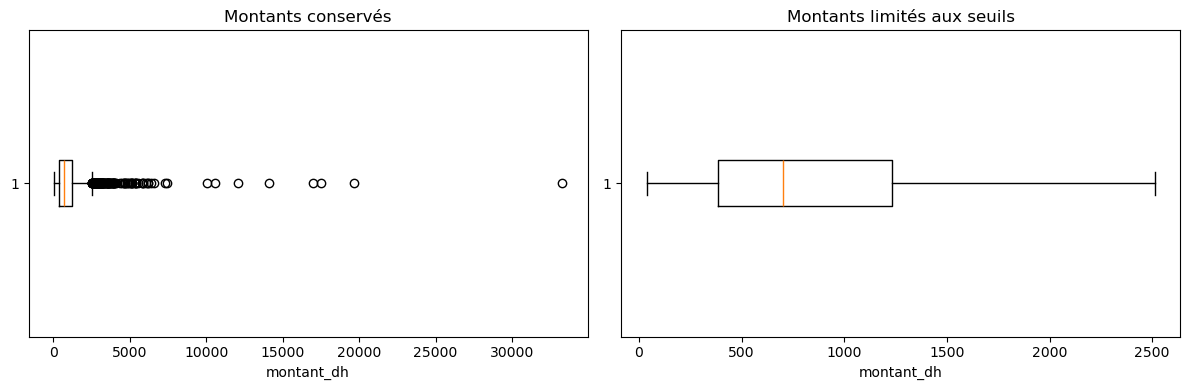

In [14]:
# Les seuils sont choisis sur le groupe de référence (borne_basse, borne_haute).
m_limite = m_ref.clip(lower=borne_basse, upper=borne_haute)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(m_ref, vert=False)
axes[0].set_title("Montants conservés")
axes[0].set_xlabel("montant_dh")
axes[1].boxplot(m_limite, vert=False)
axes[1].set_title("Montants limités aux seuils")
axes[1].set_xlabel("montant_dh")
plt.tight_layout()
plt.show()
# Il faut justifier le choix : conserver garde toute l'information (y compris
# des opérations rares et peut-être frauduleuses) mais laisse des valeurs qui
# perturbent certaines méthodes ; limiter réduit l'influence des extrêmes mais
# modifie les données et peut effacer un signal utile. Le choix dépend de la
# nature des valeurs (erreur ou opération réelle).

### Question 18 : MinMaxScaler, StandardScaler, RobustScaler sur montant_dh

In [15]:

ref_m = X_ref[["montant_dh"]]
ver_m = X_ver[["montant_dh"]]
scalers = {
    "MinMax": MinMaxScaler(),
    "Z-score": StandardScaler(),
    "Robuste": RobustScaler(),
}
ref_trans, ver_trans = {}, {}
for nom, sc in scalers.items():
    sc.fit(ref_m)                              # paramètres calculés sur la référence
    ref_trans[nom] = sc.transform(ref_m).ravel()
    ver_trans[nom] = sc.transform(ver_m).ravel()   # sans recalculer
    print(nom, "-> vérification : min = {:.3f}, max = {:.3f}".format(
        np.nanmin(ver_trans[nom]), np.nanmax(ver_trans[nom])))

MinMax -> vérification : min = 0.002, max = 0.590
Z-score -> vérification : min = -0.691, max = 13.919
Robuste -> vérification : min = -0.722, max = 22.261


### Question 19

In [16]:
exemples = pd.DataFrame({"montant_dh": [m_ref.quantile(0.25),
                                        m_ref.quantile(0.50),
                                        m_ref.quantile(0.75),
                                        m_ref.max()]},
                        index=["habituel 1", "habituel 2", "habituel 3", "très élevé"])
for nom, sc in scalers.items():
    exemples[nom] = sc.transform(exemples[["montant_dh"]]).ravel()
print(exemples.round(3))
etendue = {nom: float(exemples[nom].iloc[:3].max() - exemples[nom].iloc[:3].min())
           for nom in scalers}
print("\nÉtalement des 3 montants habituels après transformation :",
      {k: round(v, 3) for k, v in etendue.items()})
# Min-Max est la plus perturbée : le maximum extrême fixe la borne 1, donc les
# montants habituels sont écrasés dans une toute petite zone proche de 0.
# Z-score est aussi affecté (moyenne et écart-type gonflés). RobustScaler
# est la moins perturbée : la médiane et l'IQR ne dépendent pas de l'extrême,
# donc les montants habituels gardent un étalement lisible (voir ci-dessus).

            montant_dh  MinMax  Z-score  Robuste
habituel 1     382.950   0.010   -0.472   -0.376
habituel 2     703.310   0.020   -0.233    0.000
habituel 3    1234.455   0.036    0.164    0.624
très élevé   33281.230   1.000   24.090   38.259

Étalement des 3 montants habituels après transformation : {'MinMax': 0.026, 'Z-score': 0.636, 'Robuste': 1.0}


            montant_dh  MinMax  Z-score  Robuste
habituel 1     393.095   0.011   -0.473   -0.371
habituel 2     710.790   0.020   -0.238    0.000
habituel 3    1249.878   0.037    0.161    0.629
très élevé   33281.230   1.000   23.866   38.015



Étalement des 3 montants habituels après transformation : {'MinMax': 0.026, 'Z-score': 0.634, 'Robuste': 1.0}


### Question 20 

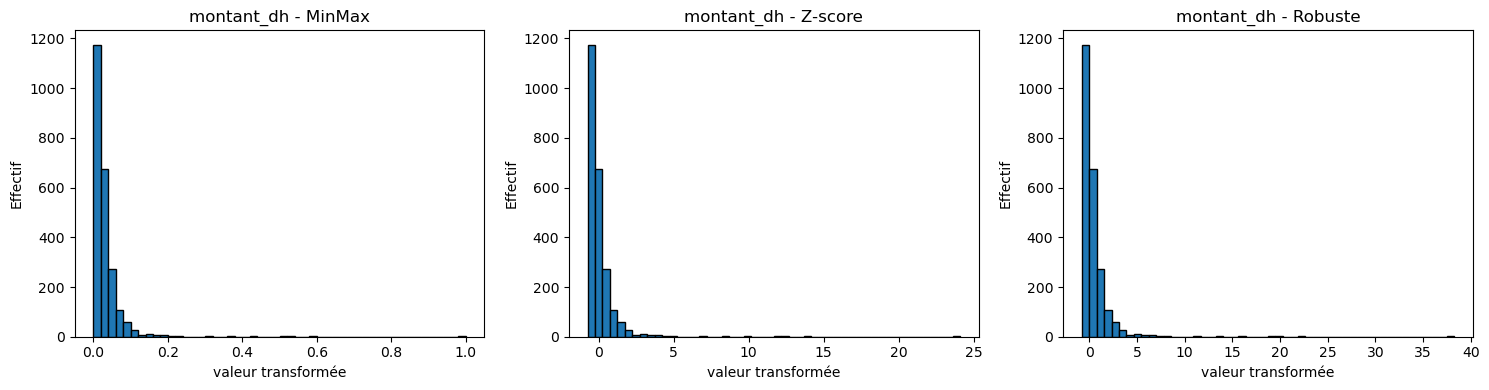

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nom in zip(axes, scalers):
    valeurs = ref_trans[nom]
    ax.hist(valeurs[~np.isnan(valeurs)], bins=50, edgecolor="black")
    ax.set_title("montant_dh - " + nom)
    ax.set_xlabel("valeur transformée")
    ax.set_ylabel("Effectif")
plt.tight_layout()
plt.show()


### Question 21 

In [18]:
petit_ref = pd.DataFrame({"montant_dh": [100.0, 200.0, 300.0, 400.0, 500.0]})
mm = MinMaxScaler().fit(petit_ref)
nouvelle = pd.DataFrame({"montant_dh": [800.0]})
print("Exemple : min = 100, max = 500, nouvelle valeur = 800")
print("Valeur transformée :", mm.transform(nouvelle)[0, 0])   # (800-100)/(500-100)
# Oui : la formule (x - min)/(max - min) donne (800-100)/(500-100) = 1,75 > 1.
# Les paramètres min et max sont figés sur la référence ; une nouvelle valeur
# plus grande que ce maximum sort de l'intervalle [0, 1].
mm_reel = MinMaxScaler().fit(ref_m)
nouveau_reel = pd.DataFrame({"montant_dh": [m_ref.max() * 1.5]})
print("Sur les données réelles, 1,5 x max de la référence ->",
      round(mm_reel.transform(nouveau_reel)[0, 0], 3))

Exemple : min = 100, max = 500, nouvelle valeur = 800
Valeur transformée : 1.75
Sur les données réelles, 1,5 x max de la référence -> 1.501


## PARTIE 4 

### Question 22 

In [19]:
eff_ref = y_ref.value_counts().sort_index()
print(eff_ref)
print("Rapport classe 0 / classe 1 : {:.2f}".format(eff_ref[0] / eff_ref[1]))

fraude
0    2225
1     211
Name: count, dtype: int64
Rapport classe 0 / classe 1 : 10.55


### Question 23 

In [20]:
ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X_ref, y_ref)
print("Avant :", y_ref.value_counts().sort_index().to_dict())
print("Après :", pd.Series(y_ros).value_counts().sort_index().to_dict())
# sample_indices_ donne l'indice de la ligne d'origine pour chaque ligne finale.
copies = X_ref.iloc[ros.sample_indices_].reset_index(drop=True)
print("Toutes les lignes finales sont des lignes de X_ref copiées :",
      copies.equals(X_ros.reset_index(drop=True)))
# Oui : le suréchantillonnage aléatoire ne crée que des copies exactes de
# lignes existantes de la classe minoritaire (tirage avec remise).

Avant : {0: 2225, 1: 211}
Après : {0: 2225, 1: 2225}
Toutes les lignes finales sont des lignes de X_ref copiées : True


### Question 24

In [21]:
rus = RandomUnderSampler(random_state=42)
X_rus, y_rus = rus.fit_resample(X_ref, y_ref)
print("Avant :", y_ref.value_counts().sort_index().to_dict())
print("Après :", pd.Series(y_rus).value_counts().sort_index().to_dict())
print("Lignes conservées :", len(X_rus), "| Lignes supprimées :", len(X_ref) - len(X_rus))
# Risque : on jette beaucoup de lignes de la classe majoritaire, donc on perd
# de l'information (cas normaux variés) et le jeu devient petit.

Avant : {0: 2225, 1: 211}
Après : {0: 211, 1: 211}
Lignes conservées : 422 | Lignes supprimées : 2014


### Question 25 

In [22]:
rng = np.random.RandomState(42)
# Petit exemple : 30 opérations normales et 6 fraudes décrites par 2 variables.
maj = rng.normal(loc=[500, 3], scale=[100, 1], size=(30, 2))
mino = rng.normal(loc=[900, 6], scale=[120, 1], size=(6, 2))
X_ex = pd.DataFrame(np.vstack([maj, mino]), columns=["montant", "nb_ops"])
y_ex = np.array([0] * 30 + [1] * 6)

smote = SMOTE(k_neighbors=3, random_state=42)
X_sm, y_sm = smote.fit_resample(X_ex, y_ex)
synth = X_sm.iloc[len(X_ex):]          # lignes ajoutées = synthétiques
reelles_mino = X_ex[y_ex == 1]
print("Classe minoritaire avant :", (y_ex == 1).sum(), "| après :", (y_sm == 1).sum())
print("\nObservations réelles de la classe minoritaire :")
print(reelles_mino.round(2))
print("\nQuelques observations synthétiques :")
print(synth.head(3).round(2))

# On vérifie sur une observation synthétique qu'elle est située sur le segment
# entre deux observations réelles : x_synth = x_a + lambda * (x_b - x_a),
# avec lambda entre 0 et 1.
s = synth.iloc[0].values
trouve = False
for i in range(len(reelles_mino)):
    for j in range(len(reelles_mino)):
        if i == j:
            continue
        a, b = reelles_mino.iloc[i].values, reelles_mino.iloc[j].values
        lam = (s - a) / (b - a)
        if np.allclose(lam[0], lam[1], atol=1e-6) and 0 <= lam[0] <= 1:
            print("\nValeur synthétique {} = A {} + {:.3f} x (B - A), avec B = {}".format(
                s.round(2), a.round(2), lam[0], b.round(2)))
            trouve = True
            break
    if trouve:
        break
print("La valeur synthétique est-elle identique à une valeur réelle ?",
      any(np.allclose(s, r) for r in reelles_mino.values))
# SMOTE ne copie pas : il choisit une observation minoritaire, un de ses
# voisins minoritaires, puis crée un point nouveau sur le segment qui les relie.

Classe minoritaire avant : 6 | après : 30

Observations réelles de la classe minoritaire :
    montant  nb_ops
30   842.50    5.81
31   767.24    4.80
32   997.50    7.36
33   891.36    7.00
34   943.40    5.35
35   943.37    7.54

Quelques observations synthétiques :
    montant  nb_ops
36   950.95    7.51
37   980.21    6.72
38   914.79    7.24

Valeur synthétique [950.95   7.51] = A [997.5    7.36] + 0.860 x (B - A), avec B = [943.37   7.54]
La valeur synthétique est-elle identique à une valeur réelle ? False


### Question 26 

In [23]:
print("""SMOTE calcule des interpolations (moyennes pondérées). Appliqué à des
colonnes one-hot (0/1), il peut produire des valeurs comme 0,4 ou 0,7, qui ne
correspondent à aucune catégorie valide (ni 0, ni 1) ; plusieurs colonnes d'une
même variable peuvent aussi cesser de s'exclure mutuellement.
Méthode conçue pour les données mêlant nombres et catégories : SMOTENC
(SMOTE-NC, « Nominal and Continuous »).""")

SMOTE calcule des interpolations (moyennes pondérées). Appliqué à des
colonnes one-hot (0/1), il peut produire des valeurs comme 0,4 ou 0,7, qui ne
correspondent à aucune catégorie valide (ni 0, ni 1) ; plusieurs colonnes d'une
même variable peuvent aussi cesser de s'exclure mutuellement.
Méthode conçue pour les données mêlant nombres et catégories : SMOTENC
(SMOTE-NC, « Nominal and Continuous »).


### Question 27

In [25]:
tableau = pd.DataFrame({
    "Référence avant": y_ref.value_counts().sort_index(),
    "Référence après suréchantillonnage": pd.Series(y_ros).value_counts().sort_index(),
    "Référence après sous-échantillonnage": pd.Series(y_rus).value_counts().sort_index(),
    "Vérification (inchangée)": y_ver.value_counts().sort_index(),
})
tableau.index.name = "fraude"
print(tableau)
# Non, le groupe de vérification ne doit pas changer : il doit rester
# représentatif de la réalité (avec la vraie proportion de fraudes) pour
# juger honnêtement la préparation. Le rééquilibrage ne s'applique qu'au
# groupe de référence.

        Référence avant  Référence après suréchantillonnage  Référence après sous-échantillonnage  Vérification (inchangée)
fraude                                                                                                                     
0                  2225                                2225                                   211                       556
1                   211                                2225                                   211                        53


## PARTIE 5 — Vérifier et enregistrer les données préparées

### Question 28

In [26]:
transformateur = ColumnTransformer([
    ("num", Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("echelle", RobustScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputation", SimpleImputer(strategy="most_frequent")),
        ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
])
print(transformateur)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputation',
                                                  SimpleImputer(strategy='median')),
                                                 ('echelle', RobustScaler())]),
                                 ['montant_dh', 'anciennete_mois', 'nb_ops_24h',
                                  'heure']),
                                ('cat',
                                 Pipeline(steps=[('imputation',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encodage',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['canal', 'appareil', 'region',
                                  'international'])])


### Question 29

In [27]:
Xref_final = transformateur.fit_transform(X_ref)   # paramètres : référence seulement
Xver_final = transformateur.transform(X_ver)       # même transformateur, sans refit
print("Référence :", Xref_final.shape, "| Vérification :", Xver_final.shape)
print("Nombre de colonnes identique :", Xref_final.shape[1] == Xver_final.shape[1])
print("Valeurs manquantes - référence    :", int(np.isnan(Xref_final).sum()))
print("Valeurs manquantes - vérification :", int(np.isnan(Xver_final).sum()))
noms_colonnes = transformateur.get_feature_names_out()
print("Colonnes obtenues :", list(noms_colonnes))

Référence : (2436, 18) | Vérification : (609, 18)
Nombre de colonnes identique : True
Valeurs manquantes - référence    : 0
Valeurs manquantes - vérification : 0
Colonnes obtenues : ['num__montant_dh', 'num__anciennete_mois', 'num__nb_ops_24h', 'num__heure', 'cat__canal_agence', 'cat__canal_application', 'cat__canal_site_web', 'cat__canal_telephone', 'cat__appareil_mobile', 'cat__appareil_ordinateur', 'cat__appareil_terminal', 'cat__region_Autre', 'cat__region_Casablanca-Settat', 'cat__region_Draa-Tafilalet', 'cat__region_Marrakech-Safi', 'cat__region_Souss-Massa', 'cat__international_non', 'cat__international_oui']


### Question 30

In [28]:
ligne_inconnue = X_ver.iloc[[0]].copy()
ligne_inconnue["canal"] = "distributeur_automatique"   # modalité absente de la référence
sortie = transformateur.transform(ligne_inconnue)       # aucune erreur
cols_canal = [i for i, n in enumerate(noms_colonnes) if n.startswith("cat__canal_")]
print("Transformation réussie, dimension :", sortie.shape)
print("Colonnes one-hot de canal pour cette ligne :", sortie[0, cols_canal])
# handle_unknown="ignore" : une modalité inconnue n'est pas une erreur ; elle
# est encodée par des 0 dans toutes les colonnes one-hot de cette variable.
# Sans cette option, OneHotEncoder lèverait une erreur pour la nouvelle catégorie.

Transformation réussie, dimension : (1, 18)
Colonnes one-hot de canal pour cette ligne : [0. 0. 0. 0.]


### Question 31 

In [29]:

joblib.dump(transformateur, "transformateur_TP2.joblib")
transformateur_recharge = joblib.load("transformateur_TP2.joblib")
echantillon = X_ver.head(5)
sortie_originale = transformateur.transform(echantillon)
sortie_rechargee = transformateur_recharge.transform(echantillon)   # pas de refit
print("Mêmes valeurs après rechargement :",
      np.allclose(sortie_originale, sortie_rechargee))

Mêmes valeurs après rechargement : True


### Question 32 : bilan

In [31]:
#Justification des principaux choix
#Doublons supprimés : une même opération comptée plusieurs fois fausserait les statistiques.
#Identifiants et resultat_enquete exclus : les identifiants n’ont pas de sens numérique. resultat_enquete est connu après coup, donc c’est une fuite d’information.
#Paramètres calculés sur la référence seulement : cela évite la fuite d’information vers le groupe de vérification.
#Médiane et RobustScaler : ils sont peu sensibles aux montants extrêmes, que l’on garde car ils peuvent être des opérations réelles.
#One-hot avec handle_unknown="ignore" : il n’y a pas d’ordre artificiel entre catégories, et une catégorie nouvelle ne provoque pas d’erreur.
#Rééquilibrage uniquement sur la référence : le groupe de vérification garde la vraie proportion de fraudes, ce qui permet un contrôle honnête.